In [60]:
import gc
from scipy.io import loadmat
from probeinterface import Probe
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.extractors as se
import spikeinterface.sorters as ss
import spikeinterface.curation as scur
from spikeinterface.sortingcomponents.motion import estimate_motion, interpolate_motion

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *

GEOM_PATH = rcp.resolve_probe_geom_path(PARAMS, REPO_ROOT, session_key=None)
NPRW_CFG     = PARAMS.probes.get("NPRW")
INTAN_STREAM = NPRW_CFG.get("neural_data_stream")
RADII        = (NPRW_CFG.get("local_radius_inner"), NPRW_CFG.get("local_radius_outer"))

global_job_kwargs = dict(n_jobs=PARAMS.parallel_jobs, chunk_duration=PARAMS.chunk)
si.set_global_job_kwargs(**global_job_kwargs)
job_kwargs = dict(n_jobs=-1, progress_bar=True, chunk_duration="1s")

DRIFT_CKPT = OUT_BASE / "checkpoints" / "NPRW_drift"
SORT_CKPT  = OUT_BASE / "checkpoints" / "sorting_results" / "NPRW_concat"
DRIFT_CKPT.mkdir(parents=True, exist_ok=True)
SORT_CKPT.mkdir(parents=True, exist_ok=True)

# 
#     This script preprocesses the Fastigial Intan data.
#     Input:
#         .rhs files from Intan
#     Output:
#         Checkpoint after preprocessing
#         Checkpoint after thresholding and calculating MUA peak locations and firing rate
# 

In [61]:
# Load Geometry
mat_probe = loadmat(Path(GEOM_PATH))
intan_geom = {"x": mat_probe["xcoords"].ravel(), "y": mat_probe["ycoords"].ravel()}
assert intan_geom["x"].size == intan_geom["y"].size
if "chanMap0ind" not in mat_probe:
    raise ValueError("No 0-based chanmap in .mat geometry file.")
intan_probe_mapping = mat_probe["chanMap0ind"].ravel()
if intan_probe_mapping.size != intan_geom["x"].size:
    raise ValueError("device_index_0based length != #contacts")

nprw_probe = Probe(ndim=2)
nprw_probe.set_contacts(
    positions=np.c_[intan_geom["x"], intan_geom["y"]],
    shapes="square", shape_params={"width": 12.0},
)
nprw_probe.set_device_channel_indices(intan_probe_mapping)

In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt

def generate_template(
    chn_data: np.ndarray,  # (NSTIM, interpulse_len)
    template_mode: str,
    repeat_boundaries: np.ndarray,  # 0-based block boundary indices
    window_size: int = 3,
    pca_k: int = 3,
) -> np.ndarray:
    """Generate pulse-by-pulse artifact templates."""
    NSTIM, interpulse_len = chn_data.shape
    template = np.zeros_like(chn_data)
    w = np.linspace(0, 1, interpulse_len)

    # Build is_first_pulse mask
    is_first_pulse = np.zeros(NSTIM, dtype=bool)
    for b in range(len(repeat_boundaries) - 1):
        is_first_pulse[repeat_boundaries[b]] = True

    if template_mode == "local":
        for i in range(NSTIM):
            if is_first_pulse[i]:
                prev_first_idxs = np.where(is_first_pulse[:i])[0]
                if len(prev_first_idxs) >= 1:
                    n_use = min(3, len(prev_first_idxs))
                    ref_idxs = prev_first_idxs[-n_use:]
                    base = chn_data[ref_idxs].mean(axis=0)
                    t = base - base[0]
                    template[i] = t + w * (-t[-1])
                continue
            count = 0
            j = i - 1
            prev_pulses = []
            while j >= 0 and count < window_size:
                if not is_first_pulse[j]:
                    prev_pulses.append(chn_data[j])
                    count += 1
                j -= 1
            if count > 0:
                base = np.stack(prev_pulses).mean(axis=0)
            else:
                base = np.zeros(interpulse_len)
            t = base - base[0]
            template[i] = t + w * (-t[-1])

    elif template_mode == "pca":
        from sklearn.decomposition import PCA
        num_blocks = len(repeat_boundaries) - 1
        for b in range(num_blocks):
            i_start = repeat_boundaries[b]
            i_end   = repeat_boundaries[b + 1]

            # First pulse correction
            prev_first_idxs = np.where(is_first_pulse[:i_start])[0]
            if len(prev_first_idxs) > 0:
                n_use = min(3, len(prev_first_idxs))
                base = chn_data[prev_first_idxs[-n_use:]].mean(axis=0)
            else:
                base = np.zeros(interpulse_len)
            t = base - base[0]
            template[i_start] = t + w * (-t[-1])

            # PCA on rest of block
            if i_end > i_start + 1:
                pca_indices = np.arange(i_start + 1, i_end)
                X = chn_data[pca_indices]
                X_centered = X - X.mean(axis=1, keepdims=True)
                k = min(pca_k, X_centered.shape[0], X_centered.shape[1])
                pca = PCA(n_components=k)
                score = pca.fit_transform(X_centered)
                recon = pca.inverse_transform(score) + X.mean(axis=1, keepdims=True)
                t = recon - recon[:, [0]]
                drift = w[np.newaxis, :] * (-t[:, [-1]])
                template[pca_indices] = t + drift

    return template


def template_subtraction(
    amplifier_data: np.ndarray,  # (n_samples,) float
    trigs: np.ndarray,           # (NSTIM, 2) [beg, end] in samples
    params: dict,
    template_mode: str,
    repeat_boundaries: np.ndarray,  # block boundary indices (0-based)
    num_repeats: int,
    num_pulse: int,
) -> np.ndarray:
    """Artifact removal via template subtraction + drift correction."""
    amplifier_data = amplifier_data.astype(np.float64).copy()

    buffer           = params["buffer"]
    template_leeway  = params["template_leeway"]
    stim_neural_delay = params["stim_neural_delay"]
    window_size      = params["movmean_window"]
    med_filt_range   = params["med_filt_range"]
    gauss_filt_range = params["gauss_filt_range"]
    pca_k            = params["pca_k"]
    NSTIM            = trigs.shape[0]

    trigs_beg = trigs[:, 0]
    trigs_end = trigs[:, 1] + stim_neural_delay

    # ── Step 1: Block-level drift removal ─────────────────────────────────
    for r in range(num_repeats):
        idx = np.arange(repeat_boundaries[r], repeat_boundaries[r + 1])
        full_range_start = trigs_end[idx[0]] - 4
        if r < num_repeats - 1:
            range_end = trigs_beg[repeat_boundaries[r + 1]] - 1
        else:
            range_end = trigs_end[idx[-1]] + buffer

        if full_range_start < 0 or range_end >= len(amplifier_data):
            continue

        raw_block = amplifier_data[full_range_start:range_end + 1].copy()

        # Moving median
        med_filtered = np.array([
            np.median(raw_block[max(0, i - med_filt_range // 2): i + med_filt_range // 2 + 1])
            for i in range(len(raw_block))
        ])

        # Gaussian filter
        sigma = gauss_filt_range / 5.0
        gauss_filtered = gaussian_filter1d(med_filtered, sigma=sigma)
        amplifier_data[full_range_start:range_end + 1] -= gauss_filtered

    # ── Step 2: Template subtraction ──────────────────────────────────────
    interpulse_len = int(trigs_end[0] - trigs_beg[0] + 1) + 2 * template_leeway
    chn_data = np.full((NSTIM, interpulse_len), np.nan)

    for i in range(NSTIM):
        seg_start = trigs_beg[i] - template_leeway
        seg_end   = trigs_end[i] + template_leeway
        if seg_start < 0 or seg_end >= len(amplifier_data):
            continue
        chn_data[i] = amplifier_data[seg_start:seg_end + 1]

    # Convert repeat_boundaries to 0-based block start indices for generate_template
    block_starts = np.array(repeat_boundaries[:-1], dtype=int)
    block_ends   = np.array(repeat_boundaries[1:],  dtype=int)
    boundaries   = np.concatenate([block_starts, [block_ends[-1]]])

    template = generate_template(chn_data, template_mode, boundaries, window_size, pca_k)

    for i in range(NSTIM):
        seg_start = trigs_beg[i] - template_leeway
        seg_end   = trigs_end[i] + template_leeway
        if seg_start < 0 or seg_end >= len(amplifier_data):
            continue
        amplifier_data[seg_start:seg_end + 1] -= template[i]

    # ── Step 3: Interpulse drift correction ───────────────────────────────
    for i in range(NSTIM - 1):
        end_i    = trigs_end[i]
        beg_next = trigs_beg[i + 1]
        mid1 = int(round((end_i + trigs_beg[i]) / 2))
        mid2 = int(round((beg_next + trigs_end[i + 1]) / 2))
        if mid1 >= mid2 or mid2 >= len(amplifier_data):
            continue
        seg_idx = np.arange(mid1, mid2 + 1)
        template_end_val = amplifier_data[trigs_end[i]]
        n = len(seg_idx)
        drift = np.arange(n) / (n - 1) * (-template_end_val) if n > 1 else np.zeros(1)
        amplifier_data[seg_idx] += drift

    return amplifier_data


def template_subtraction_all_parallel(
    neural_data: np.ndarray,      # (n_channels, n_samples)
    template_params: dict,
    template_mode: str,
    stim_result,                  # StimTriggerResult from extract_stim_triggers_and_blocks
    n_jobs: int = -1,
) -> np.ndarray:
    """Run template subtraction across all channels in parallel."""
    from joblib import Parallel, delayed

    trigs             = stim_result.trigger_pairs          # (NSTIM, 2)
    block_bounds      = stim_result.block_bounds_samples   # (n_blocks, 2)
    n_channels, n_samples = neural_data.shape
    num_repeats = len(block_bounds)

    # Build repeat_boundaries as pulse indices (matching MATLAB convention)
    # Find which pulse index starts each block
    pulse_starts = trigs[:, 0]
    repeat_boundaries = [0]
    for b in range(len(block_bounds)):
        block_end_samp = block_bounds[b, 1]
        # find last pulse in this block
        in_block = np.where(pulse_starts <= block_end_samp)[0]
        if len(in_block):
            repeat_boundaries.append(int(in_block[-1]) + 1)
    repeat_boundaries = np.array(repeat_boundaries, dtype=int)
    num_repeats = len(repeat_boundaries) - 1
    num_pulse   = trigs.shape[0] / num_repeats

    def process_channel(ch):
        return template_subtraction(
            neural_data[ch].astype(np.float64),
            trigs, template_params, template_mode,
            repeat_boundaries, num_repeats, num_pulse,
        )

    results = Parallel(n_jobs=n_jobs, prefer="threads")(
        delayed(process_channel)(ch) for ch in tqdm(range(n_channels), desc="artifact correction")
    )
    return np.stack(results).astype(np.float32)

: 

In [12]:
from tqdm import tqdm
import h5py
import gc
from pathlib import Path

BIN_CKPT = OUT_BASE / "checkpoints" / "NPRW_binary"
BIN_CKPT.mkdir(parents=True, exist_ok=True)

fixed_params = dict(
    NSTIM=0, buffer=25, template_leeway=15,
    stim_neural_delay=13, movmean_window=3,
    med_filt_range=25, gauss_filt_range=25, pca_k=3,
)
STIM_STREAM = NPRW_CFG.get("stim_data_stream")


def load_session_to_bin(
    sess: Path,
    bin_path: Path,
    intan_probe_mapping: np.ndarray,
    nprw_probe,
    fixed_params: dict,
    stim_stream: str,
    n_channels: int = 128,
    fs: float = 30000.0,
):
    pca_path = sess / "neural_data_artifact_removed_pca.mat"

    if pca_path.exists():
        # ── Path A: MATLAB artifact-corrected .mat → chunked binary ───────
        tqdm.write(f"  using artifact-corrected: {pca_path.name}")
        key = "artifact_removed_data"
        with h5py.File(pca_path, "r") as f:
            dataset       = f[key]
            shape         = dataset.shape
            chunk_size    = 30000 * 60
            is_transposed = shape[0] > shape[1]
            n_samples_mat = shape[0] if is_transposed else shape[1]

            with open(bin_path, 'wb') as f_bin:
                for start in tqdm(range(0, n_samples_mat, chunk_size), desc=f"  {sess.name}", leave=False):
                    end   = min(start + chunk_size, n_samples_mat)
                    chunk = dataset[start:end, :] if is_transposed else dataset[:, start:end].T
                    chunk.astype(np.float32).tofile(f_bin)
        tqdm.write(f"  saved binary -> {bin_path}")

    else:
        # ── Path B: load .rhs, extract stim, artifact correct, save binary
        tqdm.write(f"  no _pca.mat found, loading .rhs")
        rec_raw     = se.read_split_intan_files(sess, mode="concatenate", stream_name=INTAN_STREAM, use_names_as_ids=True)
        rec_raw     = spre.unsigned_to_signed(rec_raw)
        rec_raw     = rec_raw.set_probe(nprw_probe)
        rec_raw     = rcp.reorder_recording_to_geometry(rec_raw, intan_probe_mapping)
        neural_data = rec_raw.get_traces().T.astype(np.float32)  # (n_channels, n_samples)

        try:
            stim_arrays = rcp.extract_stim_npz(
                sess=sess, out_dir=NPRW_AUX_DATA,
                stim_stream_name=stim_stream,
                chanmap_perm=intan_probe_mapping,
            )
            if stim_arrays is not None and stim_arrays["trigger_pairs"].shape[0] > 0:
                tqdm.write(f"  running artifact correction ({stim_arrays['trigger_pairs'].shape[0]} pulses)")
                stim_result = rcp.StimTriggerResult(
                    active_channels=stim_arrays["active_channels"],
                    trigger_pairs=stim_arrays["trigger_pairs"],
                    block_bounds_samples=stim_arrays["block_bounds_samples"],
                    pulse_sizes=stim_arrays["pulse_sizes"],
                )
                neural_data = template_subtraction_all_parallel(
                    neural_data=neural_data,
                    template_params=fixed_params,
                    template_mode="pca",
                    stim_result=stim_result,
                    n_jobs=-1,
                )
                tqdm.write(f"  artifact correction done")
            else:
                tqdm.write(f"  no stim triggers, skipping artifact correction")
        except Exception as e:
            tqdm.write(f"  stim extraction failed ({e}), skipping artifact correction")

        neural_data.T.tofile(bin_path)
        tqdm.write(f"  saved binary -> {bin_path}")

# ── Main loading loop ──────────────────────────────────────────────────────
sess_folders = rcp.list_intan_sessions(INTAN_ROOT)

print(f"Found {len(sess_folders)} Intan sessions")

per_session_recs = []
for sess in tqdm(sess_folders, desc="Loading sessions"):
    bin_path   = BIN_CKPT / f"{sess.name}_neural.bin"
    n_channels = 128
    fs         = 30000.0

    if bin_path.exists():
        tqdm.write(f"[{sess.name}] binary exists, loading directly")
    else:
        tqdm.write(f"[{sess.name}] loading and converting to binary")
        load_session_to_bin(
            sess=sess,
            bin_path=bin_path,
            intan_probe_mapping=intan_probe_mapping,
            nprw_probe=nprw_probe,
            fixed_params=fixed_params,
            stim_stream=STIM_STREAM,
            n_channels=n_channels,
            fs=fs,
        )
        gc.collect()

    rec = si.BinaryRecordingExtractor(
        file_paths=[bin_path],
        sampling_frequency=fs,
        num_channels=n_channels,
        dtype="float32",
        time_axis=0,
    )
    rec = rec.set_probe(nprw_probe)
    rec = rcp.reorder_recording_to_geometry(rec, intan_probe_mapping)
    per_session_recs.append(rec)
    tqdm.write(f"  loaded {sess.name}: {rec.get_total_duration():.1f}s")

Found 17 Intan sessions


Loading sessions: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:00<00:00, 202.69it/s]

[BL_closed_loop_STIM_003_250528_140952] binary exists, loading directly
  loaded BL_closed_loop_STIM_003_250528_140952: 290.2s
[BL_closed_loop_STIM_003_250528_143512] binary exists, loading directly
  loaded BL_closed_loop_STIM_003_250528_143512: 93.9s
[BL_closed_loop_STIM_003_250528_143802] binary exists, loading directly
  loaded BL_closed_loop_STIM_003_250528_143802: 225.6s
[BL_closed_loop_STIM_003_250528_144603] binary exists, loading directly
  loaded BL_closed_loop_STIM_003_250528_144603: 262.6s
[BL_closed_loop_STIM_003_250528_145904] binary exists, loading directly
  loaded BL_closed_loop_STIM_003_250528_145904: 387.9s
[BL_closed_loop_STIM_003_250528_150615] binary exists, loading directly
  loaded BL_closed_loop_STIM_003_250528_150615: 2.0s
[BL_closed_loop_STIM_003_250528_150847] binary exists, loading directly
  loaded BL_closed_loop_STIM_003_250528_150847: 2.3s
[BL_closed_loop_STIM_003_250528_152226] binary exists, loading directly
  loaded BL_closed_loop_STIM_003_250528_1522

## Plotting stim period

In [61]:
tmp_sess = 'BL_closed_loop_STIM_003_250528_145904'
bin_path = BIN_CKPT / f"{tmp_sess}_neural.bin"

rec = si.BinaryRecordingExtractor(
        file_paths=[bin_path],
        sampling_frequency=fs,
        num_channels=n_channels,
        dtype="float32",
        time_axis=0,
    )

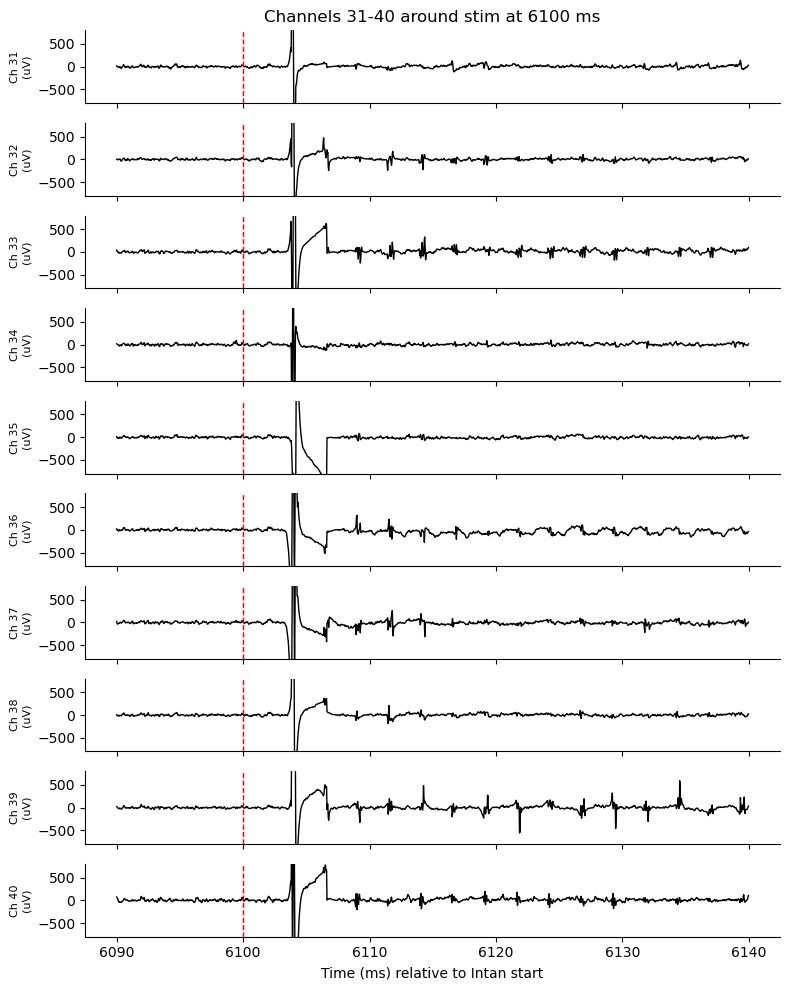

In [72]:
CH_LIST     = list(range(30, 40))  # channels 0-9
WIN_PRE_MS  = 10
WIN_POST_MS = 40

stim_timing_ms = 6100 #299
intan_start    = 199125

fs      = rec.get_sampling_frequency()
ch_ids  = rec.get_channel_ids()

stim_sample = intan_start + int(round(stim_timing_ms * 1e-3 * fs))
i0 = max(0, stim_sample - int(round(WIN_PRE_MS  * 1e-3 * fs)))
i1 = min(rec.get_num_frames(), stim_sample + int(round(WIN_POST_MS * 1e-3 * fs)))

traces = rec.get_traces(start_frame=i0, end_frame=i1,
                        channel_ids=[ch_ids[ch] for ch in CH_LIST],
                        return_in_uV=True)  # (n_samples, n_ch)
t_ms = (np.arange(i0, i1) - intan_start) / fs * 1000.0

fig, axes = plt.subplots(len(CH_LIST), 1, figsize=(8, len(CH_LIST)), sharex=True)

for i, ch in enumerate(CH_LIST):
    axes[i].plot(t_ms, traces[:, i], lw=1, color='k')
    axes[i].axvline(stim_timing_ms, color='r', lw=1, ls='--')
    axes[i].set_ylabel(f'Ch {ch+1}\n(uV)', fontsize=8)
    axes[i].spines[['right', 'top']].set_visible(False)
    axes[i].set_ylim(-800, 800)

axes[0].set_title(f'Channels {CH_LIST[0]+1}-{CH_LIST[-1]+1} around stim at {stim_timing_ms} ms')
axes[-1].set_xlabel('Time (ms) relative to Intan start')
plt.tight_layout()
plt.show()

In [13]:
stim_timing = (299, 413, 542, 669, 811, 945, 1123, 1250, 1397, 1547, 1690, 1847, 2013, 2156, 2310, 2519, 2825, 3120, 4000, 4267, 5199, 5341, 6543, 6904, 7036, 7169, 7318, 8855, 8988, 9167, 9330, 10307, 11288, 11430)
stim_timing

(299,
 413,
 542,
 669,
 811,
 945,
 1123,
 1250,
 1397,
 1547,
 1690,
 1847,
 2013,
 2156,
 2310,
 2519,
 2825,
 3120,
 4000,
 4267,
 5199,
 5341,
 6543,
 6904,
 7036,
 7169,
 7318,
 8855,
 8988,
 9167,
 9330,
 10307,
 11288,
 11430)

In [38]:
# Concatenate
rec_concat = si.concatenate_recordings(per_session_recs)
print(f"Concatenated: {rec_concat.get_total_duration():.1f}s, {rec_concat.get_num_channels()} channels")

Concatenated: 2786.2s, 128 channels


In [39]:
# # Filter & re-reference
# rec_concat = rec_concat.astype('float32')
# rec_hp  = spre.bandpass_filter(rec_concat, freq_min=float(PARAMS.highpass_hz), freq_max=PARAMS.lowpass_hz)
# rec_ref = spre.common_reference(rec_hp, reference="local", operator="median", local_radius=RADII)

In [41]:
motion, motion_info = spre.compute_motion(
    rec_concat, preset="dredge", folder=DRIFT_CKPT, output_motion_info=True, overwrite=True, **job_kwargs
)

detect and localize (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


Cross correlation:   0%|          | 0/3 [00:00<?, ?it/s]

Solve:   0%|          | 0/2 [00:00<?, ?it/s]

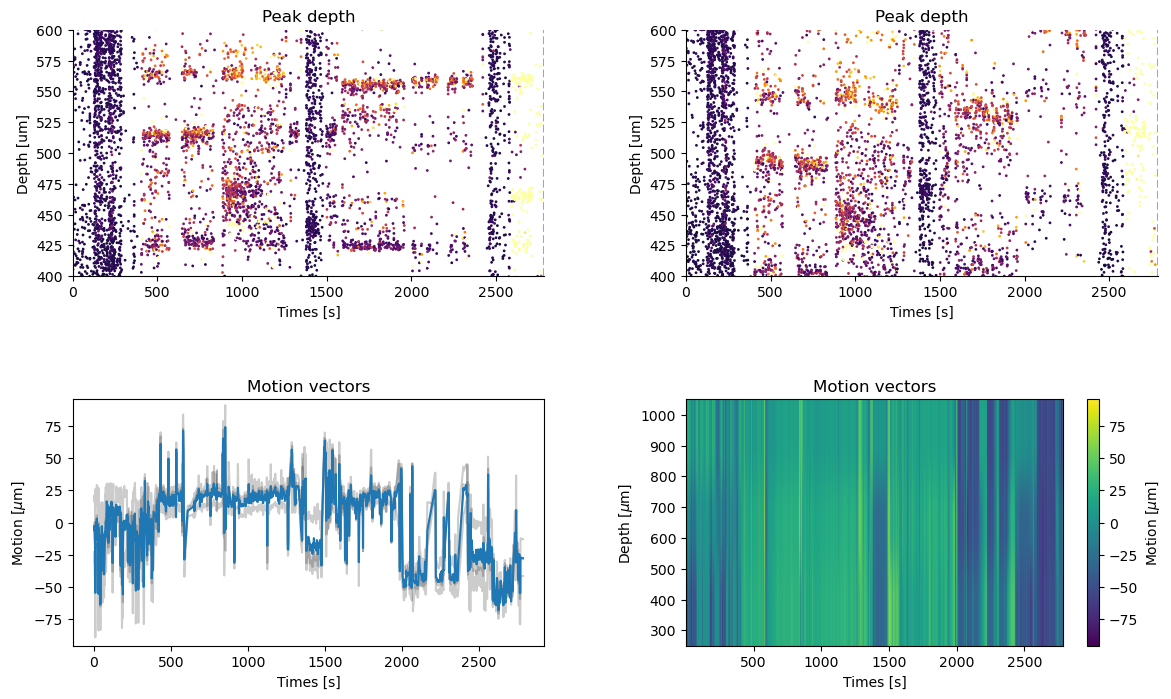

In [42]:
%matplotlib inline
from spikeinterface.widgets import plot_motion, plot_motion_info
fig = plt.figure(figsize=(14, 8))
plot_motion_info(
    motion_info, rec_concat,
    figure=fig,
    depth_lim=(400, 600),
    color_amplitude=True,
    amplitude_cmap="inferno",
    scatter_decimate=10,
)

# fig.suptitle(f"{"kilosort_like"=}")

In [43]:
from spikeinterface.sortingcomponents.motion import interpolate_motion
interpolated_recording = interpolate_motion(
    recording=rec_concat, motion=motion_info['motion'],
    border_mode="force_extrapolate"
)
interpolated_recording


interpolate_motion (InterpolateMotionRecording): 128 channels - 30.0kHz - 1 segments 
                    83,586,048 samples - 2,786.20s (46.44 minutes) - float32 dtype - 39.86 GiB

In [ ]:
# Kilosort4
sorting = ss.run_sorter(
    sorter_name="kilosort4",
    recording=interpolated_recording,
    folder=SORT_CKPT / "folder_KS4",
    remove_existing_folder=True,
    do_correction=False,
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:43<00:00, 43.52s/it]


In [ ]:
sorting = scur.remove_duplicated_spikes(sorting)
sorting = scur.remove_excess_spikes(sorting, interpolated_recording)
sorting = scur.remove_redundant_units(sorting, align=False, remove_strategy="max_spikes")
sorting.save(folder=SORT_CKPT / "sorting_curated", overwrite=True)

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


NumpyFolder (NumpyFolderSorting): 198 units - 1 segments - 30.0kHz

In [44]:
# Reload
sorting = si.load(SORT_CKPT / "sorting_curated")

In [ ]:
import shutil, pathlib
folder = SORT_CKPT / "analyzer_pre_slay"
if folder.exists():
    shutil.rmtree(folder, ignore_errors=True)
    # force-remove anything left
    import subprocess
    subprocess.run(["rm", "-rf", str(folder)], check=True)

In [51]:
# ── Phy export: post-curation, pre-SLAY ───────────────────────────────────
analyzer_precuration = si.create_sorting_analyzer(
    sorting, interpolated_recording,
    format="binary_folder",
    folder=SORT_CKPT / "analyzer_pre_slay",
    overwrite=True,
    **job_kwargs,
)
analyzer_precuration.compute(
    ["random_spikes", "waveforms", "templates", "noise_levels", "spike_amplitudes", "unit_locations"],
    **job_kwargs,
)
from spikeinterface.exporters import export_to_phy
export_to_phy(
    analyzer_precuration,
    output_folder=SORT_CKPT / "phy_pre_slay",
    **job_kwargs,
)
print(f"Phy export (pre-SLAY) -> {SORT_CKPT / 'phy_pre_slay'}")

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

compute_waveforms (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

Compute : spike_amplitudes (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

write_binary_recording (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/postprocessing/template_similarity.py:345: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  overlapping_ids = overlapping_j_list[i]


Fitting PCA:   0%|          | 0/198 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/198 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/NPRW_concat/phy_pre_slay/params.py
Phy export (pre-SLAY) -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/NPRW_concat/phy_pre_slay


AssertionError: No params file in extension waveforms folder

In [52]:
# SLAY on full concatenated sorting
from spikeinterface.curation import compute_merge_unit_groups
analyzer_concat_path = SORT_CKPT / "my_sorting_analyzer_concat"
analyzer_concat = si.create_sorting_analyzer(
    sorting, interpolated_recording,
    format="binary_folder", folder=analyzer_concat_path,
    overwrite=True, **job_kwargs,
)

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

## SNR and RP criterion before, Slay, then FR criterion

In [ ]:
# analyzer_concat.compute(
#     ["random_spikes", "templates", "noise_levels", "template_similarity", "correlograms", "quality_metrics"],
#     extension_params={
#         "quality_metrics": {
#             "metric_names": ["snr", "rp_violation"],
#             "metric_params": {"rp_violation": {"refractory_period_ms": 0.5}},
#         },
#     },
#     **job_kwargs,
# )

# qm = analyzer_concat.get_extension("quality_metrics").get_data()
# passing = qm.query("snr > 3.0 and rp_contamination < 0.2").index.tolist()
# print(f"[global QM] {len(passing)}/{len(qm)} units pass SNR/RP filter")
# analyzer_concat = analyzer_concat.select_units(passing)

# merge_groups = compute_merge_unit_groups(analyzer_concat, preset="slay", resolve_graph=True)
# if merge_groups is not None and len(merge_groups) > 0:
#     analyzer_concat = analyzer_concat.merge_units(merge_unit_groups=merge_groups)
#     print(f"[concat] {analyzer_concat.sorting.get_num_units()} units after SLAY merge")
# else:
#     print(f"[concat] no merges found, {analyzer_concat.sorting.get_num_units()} units")

# sorting_merged = analyzer_concat.sorting

estimate_templates_with_accumulator (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

[global QM] 21/21 units pass SNR/RP filter
[concat] no merges found, 21 units


/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/metrics/quality/misc_metrics.py:188: UserWarning: Operator 'median' requires 'waveforms' extension. Falling back to 'average'. To use 'median', please compute the 'waveforms' extension first with: analyzer.compute('waveforms')
  warnings.warn(


In [ ]:
# # Per-session threshold — keep units passing in ANY session
# from scipy.io import savemat
# session_boundaries = np.concatenate([[0], np.cumsum([r.get_num_samples() for r in per_session_recs])])
# good_units_any_session = set()
# sess_names = [s.name for s in sess_folders]

# for i, sess_name in enumerate(tqdm(sess_names, desc="Per-session threshold")):
#     t_start = int(session_boundaries[i])
#     t_end   = int(session_boundaries[i+1])
#     dur_s   = (t_end - t_start) / sorting_merged.get_sampling_frequency()
#     if dur_s < 10:
#         tqdm.write(f"[{sess_name}] skipping thresholding ({dur_s:.1f}s too short)")
#         continue

#     rec_sess     = interpolated_recording.frame_slice(start_frame=t_start, end_frame=t_end)
#     sorting_sess = sorting_merged.frame_slice(start_frame=t_start, end_frame=t_end)

#     analyzer_sess = si.create_sorting_analyzer(sorting_sess, rec_sess, format="memory")
#     analyzer_sess.compute(
#         ["random_spikes", "templates", "noise_levels", "quality_metrics"],
#         extension_params={
#             "quality_metrics": {
#                 "metric_names": ["firing_rate"],
#             },
#         },
#         **job_kwargs,
#     )
#     qm_sess  = analyzer_sess.get_extension("quality_metrics").get_data()
#     passing  = qm_sess.query("firing_rate > 0.1").index
#     good_units_any_session.update(passing.tolist())
#     tqdm.write(f"[{sess_name}] {len(passing)}/{len(qm_sess)} units pass thresholding ({dur_s:.1f}s)")

# tqdm.write(f"\nTotal good units across all sessions: {len(good_units_any_session)}")

# good_units_any_session = list(good_units_any_session)
# sorting_merged_filtered = sorting_merged.select_units(good_units_any_session)

## Slay, then FR SNR and RP criterion

In [ ]:
analyzer_concat.compute(
    ["random_spikes", "templates", "template_similarity", "correlograms"],
    **job_kwargs,
)

merge_groups = compute_merge_unit_groups(analyzer_concat, preset="slay", resolve_graph=True)
if merge_groups is not None and len(merge_groups) > 0:
    analyzer_concat = analyzer_concat.merge_units(merge_unit_groups=merge_groups)
    print(f"[concat] {analyzer_concat.sorting.get_num_units()} units after SLAY merge")
else:
    print(f"[concat] no merges found, {analyzer_concat.sorting.get_num_units()} units")

sorting_merged = analyzer_concat.sorting

estimate_templates_with_accumulator (workers: 12 processes fork):   0%|          | 0/2787 [00:00<?, ?it/s]

[concat] no merges found, 198 units


In [54]:
# Per-session filter: FR + SNR + RP
from scipy.io import savemat
session_boundaries = np.concatenate([[0], np.cumsum([r.get_num_samples() for r in per_session_recs])])
good_units_any_session = set()
sess_names = [s.name for s in sess_folders]

for i, sess_name in enumerate(tqdm(sess_names, desc="Per-session threshold")):
    t_start = int(session_boundaries[i])
    t_end   = int(session_boundaries[i+1])
    dur_s   = (t_end - t_start) / sorting_merged.get_sampling_frequency()
    if dur_s < 10:
        tqdm.write(f"[{sess_name}] skipping ({dur_s:.1f}s too short)")
        continue

    rec_sess     = interpolated_recording.frame_slice(start_frame=t_start, end_frame=t_end)
    sorting_sess = sorting_merged.frame_slice(start_frame=t_start, end_frame=t_end)

    analyzer_sess = si.create_sorting_analyzer(sorting_sess, rec_sess, format="memory")
    analyzer_sess.compute(
        ["random_spikes", "templates", "noise_levels", "quality_metrics"],
        extension_params={
            "quality_metrics": {
                "metric_names": ["firing_rate", "snr", "rp_violation"],
                "metric_params": {"rp_violation": {"refractory_period_ms": 0.5}},
            },
        },
        **job_kwargs,
    )
    qm_sess = analyzer_sess.get_extension("quality_metrics").get_data()
    passing = qm_sess[
        (qm_sess["firing_rate"] > 0.1) &
        (qm_sess["snr"] > 3.0) &
        (qm_sess["rp_contamination"] < 0.2)
    ].index
    good_units_any_session.update(passing.tolist())
    tqdm.write(f"[{sess_name}] {len(passing)}/{len(qm_sess)} units pass ({dur_s:.1f}s)")

print(f"\nTotal good units across all sessions: {len(good_units_any_session)}")
sorting_merged_filtered = sorting_merged.select_units(list(good_units_any_session))

Per-session threshold:   0%|                                                                                           | 0/17 [00:00<?, ?it/s]

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/73 [00:00<?, ?it/s]

estimate_templates_with_accumulator (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/metrics/quality/misc_metrics.py:188: UserWarning: Operator 'median' requires 'waveforms' extension. Falling back to 'average'. To use 'median', please compute the 'waveforms' extension first with: analyzer.compute('waveforms')
  warnings.warn(
Per-session threshold:   6%|████▉                                                                              | 1/17 [00:58<15:33, 58.35s/it]

[BL_closed_loop_STIM_003_250528_140952] 6/198 units pass (290.2s)


... (66 outputs left out)

estimate_templates_with_accumulator (workers: 12 processes fork):   0%|          | 0/67 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/metrics/quality/misc_metrics.py:188: UserWarning: Operator 'median' requires 'waveforms' extension. Falling back to 'average'. To use 'median', please compute the 'waveforms' extension first with: analyzer.compute('waveforms')
  warnings.warn(
Per-session threshold: 100%|██████████████████████████████████████████████████████████████████████████████████| 17/17 [10:35<00:00, 37.41s/it]

[BL_closed_loop_STIM_003_250528_160920] 75/198 units pass (66.8s)

Total good units across all sessions: 164


In [ ]:
# ── Phy export: post-SLAY + filtered ──────────────────────────────────────
analyzer_final = si.create_sorting_analyzer(
    sorting_merged_filtered, interpolated_recording,
    format="binary_folder",
    folder=SORT_CKPT / "analyzer_final",
    overwrite=True,
    **job_kwargs,
)
analyzer_final.compute(
    ["random_spikes", "templates", "noise_levels", "spike_amplitudes", "unit_locations"],
    **job_kwargs,
)
si.export_to_phy(
    analyzer_final,
    output_folder=SORT_CKPT / "phy_final",
    compute_pc_features=False,
    copy_binary=False,
    overwrite=True,
    **job_kwargs,
)
print(f"Phy export (final) -> {SORT_CKPT / 'phy_final'}")

## Save

In [42]:
# Split per session and save
for i, sess_name in enumerate(tqdm(sess_names, desc="Saving spike trains")):
    t_start = int(session_boundaries[i])
    t_end   = int(session_boundaries[i+1])

    spike_trains = {}
    for uid in sorting_merged_filtered.unit_ids:
        st   = sorting_merged_filtered.get_unit_spike_train(uid, segment_index=0)
        mask = (st >= t_start) & (st < t_end)
        spike_trains[str(uid)] = st[mask] - t_start

    total = sum(len(v) for v in spike_trains.values())
    tqdm.write(f"[{sess_name}] total_spikes={total}")

    out_path = OUT_BASE / "checkpoints" / "sorting_results" / sess_name / "NPRW"
    out_path.mkdir(parents=True, exist_ok=True)
    savemat(out_path / "spike_trains.mat",
            {f"unit_{k}": v for k, v in spike_trains.items()} | {"fs": float(sorting_merged_filtered.get_sampling_frequency())})

Saving spike trains:   0%|                                                                                             | 0/17 [00:00<?, ?it/s]

[BL_closed_loop_STIM_003_250528_140952] total_spikes=13955


Saving spike trains:   6%|█████                                                                                | 1/17 [00:00<00:02,  7.29it/s]

[BL_closed_loop_STIM_003_250528_143512] total_spikes=13103


Saving spike trains:  18%|███████████████                                                                      | 3/17 [00:00<00:01,  9.89it/s]

[BL_closed_loop_STIM_003_250528_143802] total_spikes=45107
[BL_closed_loop_STIM_003_250528_144603] total_spikes=47133


... (13 outputs left out)

[BL_closed_loop_STIM_003_250528_160437] total_spikes=1


Saving spike trains:  94%|███████████████████████████████████████████████████████████████████████████████     | 16/17 [17:19<01:35, 95.86s/it]

[BL_closed_loop_STIM_003_250528_160557] total_spikes=1741
[BL_closed_loop_STIM_003_250528_160920] total_spikes=321


Saving spike trains: 100%|████████████████████████████████████████████████████████████████████████████████████| 17/17 [17:19<00:00, 61.17s/it]
